# 06 · 稳定性、SQL 核对与业务情景

## 本页要回答什么

当前模型结果对开发样本规模和划分方式有多敏感？SQL 汇总能否与 Python 指标核对？在明确的成本/价值假设下，业务决策需要什么额外证据？

## 代码导航

- 稳定性：run_stability.py → criteo_uplift/stability.py。
- 冻结预测的指标扩展：scripts/run_metrics_extension.py → criteo_uplift/evaluation.py。
- SQL 核对：scripts/run_sql_audit.py → criteo_uplift/sql_audit.py。
- 样本量与经济情景：criteo_uplift/planning.py 的 plan_policy_ab()、cost_value_scenario()。
- 主要结果目录：stability_v1/、metrics_v2/、sql_audit_v1/。

这些是已经运行完成的扩展产物，本页不会重训或根据测试结果更换模型。稳定性分析排除旧测试行，但此前已看过旧测试结果，因此不能包装成全新独立确认。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'criteo_uplift').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from criteo_uplift.runtime import configure_runtime
configure_runtime()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from criteo_uplift.pipeline_io import result_directory
FIG = ROOT/'artifacts/extension_figures'
FIG.mkdir(exist_ok=True)


In [ ]:
ST = result_directory('stability_v1', ROOT)
report = json.loads((ST / 'report.json').read_text())
long = pd.read_csv(ST / 'longmetrics.csv')
agg = pd.read_csv(ST / 'aggregate.csv')
audit = pd.read_csv(ST / 'split_audit.csv')

display({
    key: report[key]
    for key in [
        'experiments', 'fitted_models', 'development_n',
        'old_test_n_excluded', 'all_old_test_row_overlaps_zero',
        'all_group_split_feature_overlaps_zero'
    ]
})
audit_columns = [c for c in ['split_method', 'n_train', 'n_validation', 'n_test', 'old_test_overlap_rows', 'group_feature_overlap_rows'] if c in audit.columns]
display(audit[audit_columns] if audit_columns else audit)

cols = [
    'split_method', 'training_fraction', 'policy',
    'incremental_per_100k_mean', 'incremental_per_100k_std',
    'vs_propensity_per_100k_mean', 'train_control_events_min',
    'train_control_events_max'
]
display(agg[cols].sort_values(['split_method', 'training_fraction', 'policy']))

## 1. 训练规模与划分方式的敏感性

**实现位置：** criteo_uplift/stability.py；结果目录 stability_v1/。

三个 seed × 25% / 50% / 100% 的嵌套训练子集使用固定验证集，误差棒为三个划分的样本标准差，不是 95% CI；这些配置共享数据，不能视为独立实验。

另做三个全规模特征组隔离划分：相同 float32 匿名特征向量不跨 train/validation，保留全部行。这不是用户 ID 分组，也不能证明真实用户无泄漏。组隔离改变验证分布，不能直接用两种切分的指标高低宣称某一种更优。

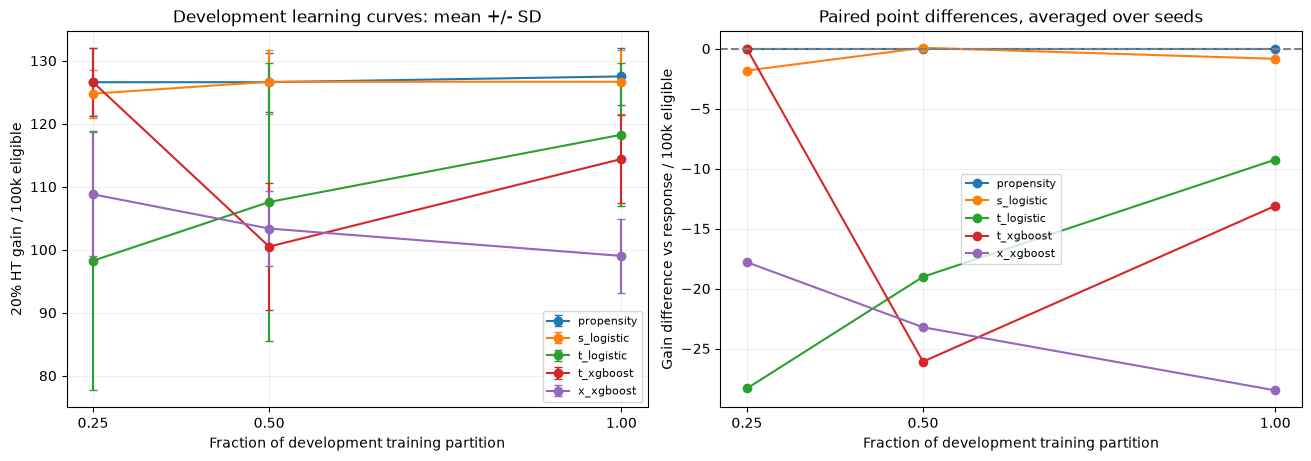

X-Learner 胜过 response 的开发配置数: 0 / 12
注意：25% 规模 T-XGBoost 和 response 指标相等；选择频率含固定候选顺序的 tie-break，不能当作获胜证据。


In [3]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
for name in ['propensity','s_logistic','t_logistic','t_xgboost','x_xgboost']:
    a=agg[(agg.split_method=='row_stratified') & (agg.policy==name)].sort_values('training_fraction')
    axes[0].errorbar(a.training_fraction,a.incremental_per_100k_mean,yerr=a.incremental_per_100k_std,marker='o',capsize=3,label=name)
    axes[1].plot(a.training_fraction,a.vs_propensity_per_100k_mean,'o-',label=name)
axes[0].set(title='Development learning curves: mean +/- SD',ylabel='20% HT gain / 100k eligible')
axes[1].axhline(0,color='gray',ls='--')
axes[1].set(title='Paired point differences, averaged over seeds',ylabel='Gain difference vs response / 100k eligible')
for ax in axes:
    ax.set_xlabel('Fraction of development training partition');ax.set_xticks([.25,.5,1]);ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.savefig(FIG/'stability_learning_curves.png',dpi=160);plt.show()
x=long[long.policy=='x_xgboost']
print('X-Learner 胜过 response 的开发配置数:',int((x.vs_propensity_per_100k>0).sum()),'/',len(x))
print('注意：25% 规模 T-XGBoost 和 response 指标相等；选择频率含固定候选顺序的 tie-break，不能当作获胜证据。')

## 2. 冻结预测的 v2 指标与配对区间

**实现位置：** scripts/run_metrics_extension.py 调用 evaluation.py；结果目录 metrics_v2/。

该扩展对已经保存的预测重算指标，不重新训练或重新选择模型。区间是固定模型、固定分配概率和给定臂样本量条件下的逐项区间，不包含训练与选型不确定性，也不是多指标同时区间。

In [ ]:
MET = result_directory('metrics_v2', ROOT)
ranking = pd.read_csv(MET / 'ranking.csv')
intervals = pd.read_csv(MET / 'ranking_intervals.csv')

ranking_cols = [c for c in [
    'policy', 'auuc_plugin', 'auuc_ht', 'qini_score_traditional',
    'qini_ht', 'relative_lift'
] if c in ranking.columns]
display(ranking[ranking_cols])

interval_cols = [c for c in [
    'metric', 'policy', 'estimate', 'ci_low', 'ci_high',
    'vs_propensity', 'vs_propensity_ci_low', 'vs_propensity_ci_high'
] if c in intervals.columns]
display(intervals[interval_cols])

chosen = intervals[intervals.metric == 'qini_score_traditional'].copy()
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
for i, row in enumerate(chosen.itertuples()):
    ax.plot([row.vs_propensity_ci_low, row.vs_propensity_ci_high], [i, i], lw=3)
    ax.plot(row.vs_propensity, i, 'o')
ax.axvline(0, color='gray', ls='--')
ax.set_yticks(range(len(chosen)), chosen.policy)
ax.set(title='Traditional Qini difference vs response: paired 95% intervals', xlabel='Unnormalized, population-fraction axes')
ax.grid(axis='x', alpha=.2)
fig.savefig(FIG / 'qini_paired_intervals.png', dpi=160)
plt.show()

## 3. SQL：核对 Python 评价口径

**实现位置：** scripts/run_sql_audit.py → criteo_uplift/sql_audit.py；结果目录 sql_audit_v1/。

SQL 从公开 CSV 派生 SQLite 表，核对主键/外键、1:1 完整连接、两臂 CVR、十分位分桶和预算排名。row_id 是原始行号，不是真实用户 ID，也没有伪造事件时间。完整查询保存在 artifacts/sql_audit_v1/queries.sql；Notebook 只展示关键核对结果，不把整份 SQL 原文铺在输出区。

In [ ]:
SQL = result_directory('sql_audit_v1', ROOT)
display(pd.read_csv(SQL / 'join_integrity.csv'))
display(pd.read_csv(SQL / 'cvr.csv'))
display(pd.read_csv(SQL / 'policy_values.csv'))
display(pd.read_csv(SQL / 'score_bins.csv').head(12))

queries_path = SQL / 'queries.sql'
query_text = queries_path.read_text()
statement_count = query_text.count(';')
print(f"完整 SQL：{queries_path.relative_to(ROOT)}")
print(f"查询文件行数：{len(query_text.splitlines())}；分号结尾语句数：{statement_count}")
print("Notebook 只展示审计结果；需要逐句学习 SQL 时打开上述 queries.sql 文件。")

## 4. 样本量与成本/价值情景

**实现位置：** criteo_uplift/planning.py 的 plan_policy_ab() 与 cost_value_scenario()。

本节输入的基线率、MDE、每次转化价值和单次触达成本都是显式假设，不是 Criteo 的真实线上 CVR、收入或成本。样本量按全部入组人群定义的策略效果计算；预算比例决定触达人数，不能直接拿预算比例除以 MDE。经济情景只回答“如果这些假设成立，结果会怎样”，不能当作已实现 ROI。

In [ ]:
from criteo_uplift.planning import plan_policy_ab, cost_value_scenario

plans = pd.DataFrame([plan_policy_ab(.003, delta) for delta in [.00015, .0003, .0006]])
plan_columns = [
    'p0_assumed', 'p1_assumed', 'absolute_mde', 'relative_mde',
    'n_policy_B', 'n_policy_A', 'n_total', 'approximate_achieved_power'
]
display(plans[plan_columns])

RUN = result_directory('conversion_1000000_seed42', ROOT)
policy_results = pd.read_csv(RUN / 'test_policies.csv')
selection = json.loads((RUN / 'selection.json').read_text())
row = policy_results[
    (policy_results.policy == selection['selected_policy']) &
    np.isclose(policy_results.budget, .2)
].iloc[0]

scenarios = []
for value in [1., 5., 10.]:
    for cost in [.001, .01, .05]:
        scenarios.append(cost_value_scenario(
            float(row.incremental_per_100k), budget=.2,
            value_per_conversion=value, contact_cost=cost,
            ci_low=float(row.ci_low), ci_high=float(row.ci_high)
        ))
scenario_table = pd.DataFrame(scenarios)
scenario_columns = [
    'budget', 'contacts', 'value_per_conversion_assumed', 'contact_cost_assumed',
    'gross_incremental_value', 'contact_cost_total', 'net_incremental_value',
    'net_ci_low_conditional', 'net_ci_high_conditional', 'break_even_contact_cost'
]
display(scenario_table[scenario_columns])
print('所有成本、价值和效果迁移都来自假设输入，不是实际收入或 ROI。')

## 5. 当前证据支持什么、不支持什么

1. 当前公开基准上，冻结的 response propensity 策略在 20% 预算下高于解析随机策略；这不是线上收入增长声明。
2. S/T/X learner 均已实现，但当前结果没有证明复杂 X-Learner 优于 response 基线；开发期配置也没有显示反转。
3. 现有学习曲线不能单独证明“扩样就会解决”；500 万/全量重训和线上策略实验尚未完成。
4. 真正上线前，需要预先冻结候选池、策略、转化窗口、主指标、成本护栏和停止规则，并通过独立线上随机实验验证。

完整的代码调用关系见 ../docs/PROJECT_PIPELINE.md；结果文件和对外表达边界见 ../docs/RESULTS_GUIDE.md。